# Disease Prediction Project

This notebook builds a complete machine learning pipeline to predict heart disease presence using the UCI Heart Disease dataset.

## Objective
To build a binary classification model that accurately predicts the presence of heart disease based on clinical parameters, comparing Logistic Regression and Random Forest models.

## Import Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

import joblib
import warnings
warnings.filterwarnings('ignore')


## Load Dataset
We fetch the dataset directly from the UCI ML Repository. Missing values are represented as '?' in the raw data, which we replace with NaN.

In [2]:

# We use the processed cleveland dataset from UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", 
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]
df = pd.read_csv(url, names=columns, na_values="?")

# The target variable is 0 (no presence) to 4. We binarize it: > 0 means disease.
df['target'] = (df['target'] > 0).astype(int)

df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Dataset Overview

In [3]:

print(f"Dataset Shape: {df.shape}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nTarget Distribution:")
print(df['target'].value_counts())
print("\nDescriptive Statistics:")
display(df.describe())


Dataset Shape: (303, 14)

Data Types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target Distribution:
target
0    164
1    139
Name: count, dtype: int64

Descriptive Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


## Exploratory Data Analysis

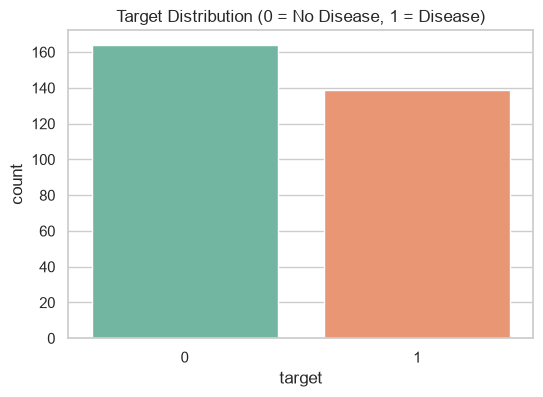

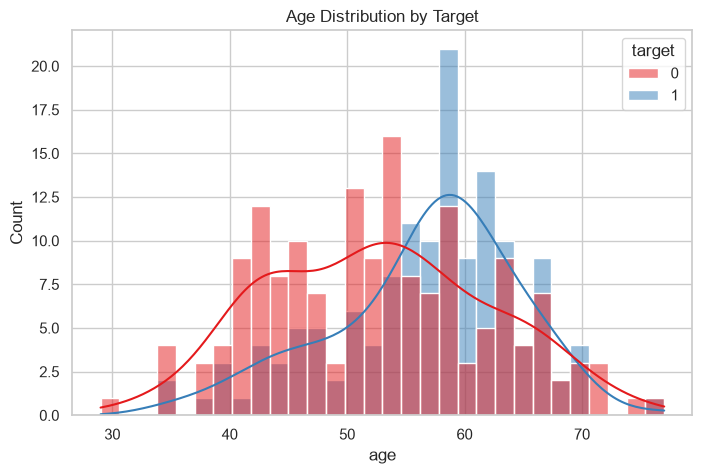

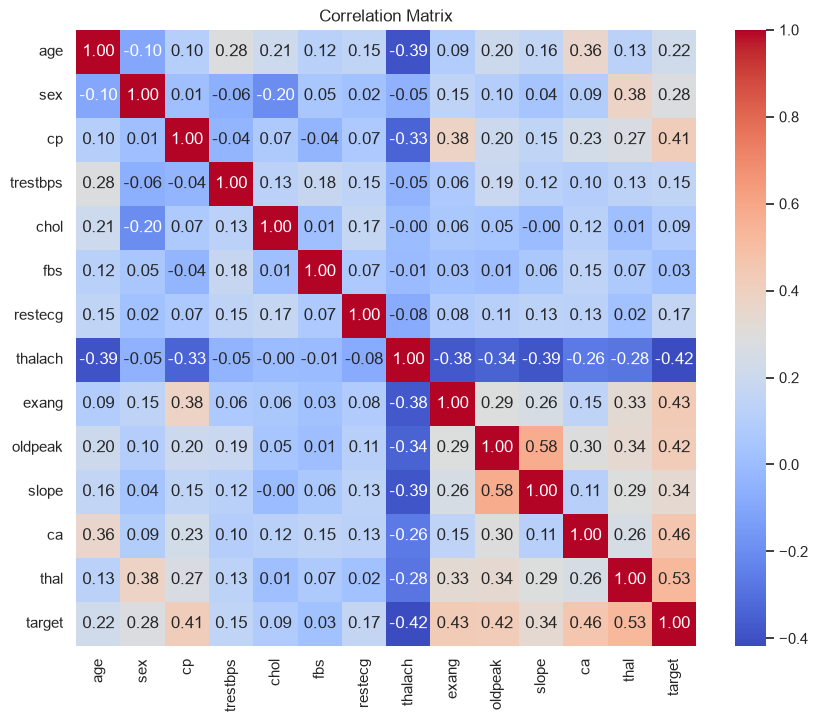

In [4]:

# Set style
sns.set_theme(style="whitegrid")

# Target Distribution Plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='Set2')
plt.title('Target Distribution (0 = No Disease, 1 = Disease)')
plt.show()

# Age vs Target
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=30, palette='Set1')
plt.title('Age Distribution by Target')
plt.show()

# Correlation Matrix
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Matrix')
plt.show()


## Feature/Target Separation

In [5]:

X = df.drop(columns=['target'])
y = df['target']

# Identify numeric and categorical features
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

print("Features separated.")


Features separated.


## Train/Test Split
We use a 80-20 split with stratification to maintain class proportions.

In [6]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")


Training set size: (242, 13)
Testing set size: (61, 13)


## Preprocessing Pipeline
Using `ColumnTransformer` to apply specific transformations to numeric and categorical columns. This prevents data leakage as imputation and scaling will be fitted only on the training data.

In [7]:

# Numeric pipeline: Impute missing values with median and scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Impute missing values with most frequent and one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])


## Model Training
We train two models: Logistic Regression and Random Forest.

In [8]:

# Logistic Regression Pipeline
logreg_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                  ('classifier', LogisticRegression(random_state=42, max_iter=1000))])

# Random Forest Pipeline
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))])

# Train models
print("Training Logistic Regression...")
logreg_pipeline.fit(X_train, y_train)

print("Training Random Forest...")
rf_pipeline.fit(X_train, y_train)
print("Training complete.")


Training Logistic Regression...
Training Random Forest...


Training complete.


## Model Evaluation and Comparison
Comparing the models across multiple metrics. In disease prediction, Recall is critical because missing a positive case (False Negative) can have severe medical consequences.

In [9]:

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

metrics_logreg = evaluate_model(logreg_pipeline, X_test, y_test)
metrics_rf = evaluate_model(rf_pipeline, X_test, y_test)

results_df = pd.DataFrame([metrics_logreg, metrics_rf], index=['Logistic Regression', 'Random Forest'])
display(results_df)


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.885246,0.83871,0.928571,0.881356,0.966450
Random Forest,0.868852,0.81250,0.928571,0.866667,0.942641


## Best Model Selection
We prioritize Recall because diagnosing patients with the disease is the most important aspect of this model. We also visualize the comparison.

Selected Best Model: Logistic Regression (Based on Recall and overall performance)


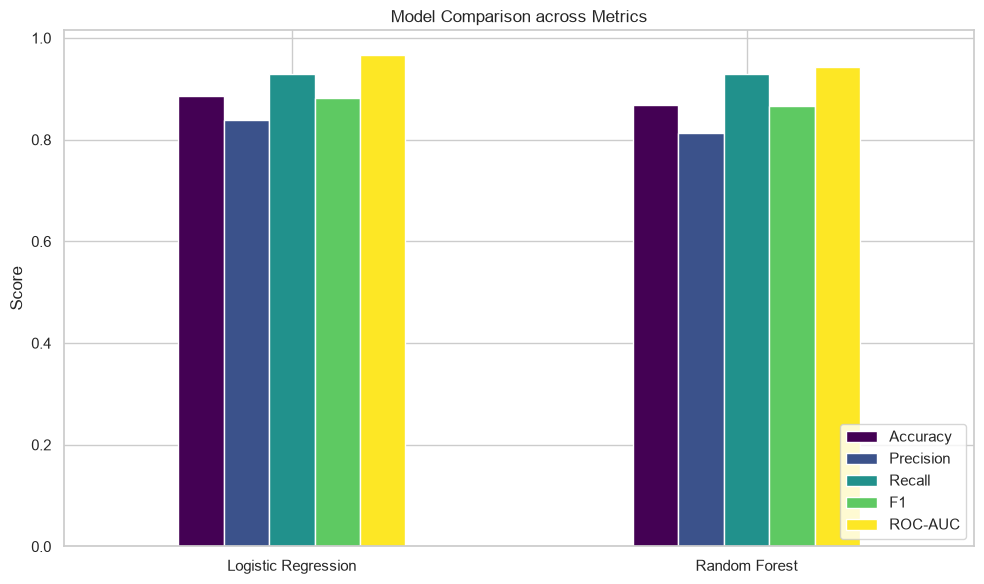

In [10]:

# We select Logistic Regression if it has competitive recall and AUC, otherwise Random Forest.
# Let's dynamically pick the one with the highest Recall as our primary criterion, breaking ties with ROC-AUC.

if results_df.loc['Logistic Regression', 'Recall'] >= results_df.loc['Random Forest', 'Recall']:
    best_model_name = 'Logistic Regression'
    best_model = logreg_pipeline
else:
    best_model_name = 'Random Forest'
    best_model = rf_pipeline

print(f"Selected Best Model: {best_model_name} (Based on Recall and overall performance)")

# Plot Model Comparison
results_df.plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title('Model Comparison across Metrics')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('results/model_comparison.png')
plt.show()


## Confusion Matrix

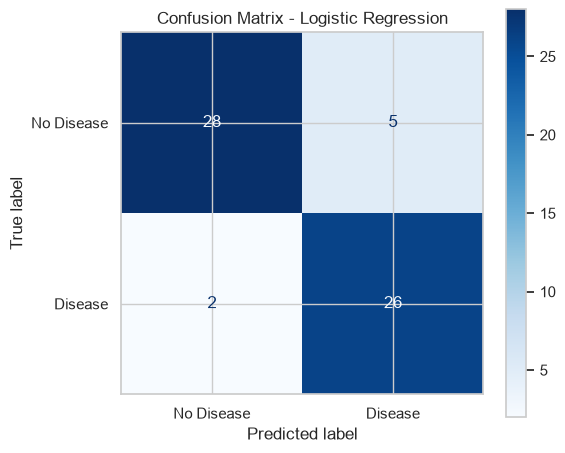

In [11]:

y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.savefig('results/confusion_matrix.png')
plt.show()


## ROC Curve

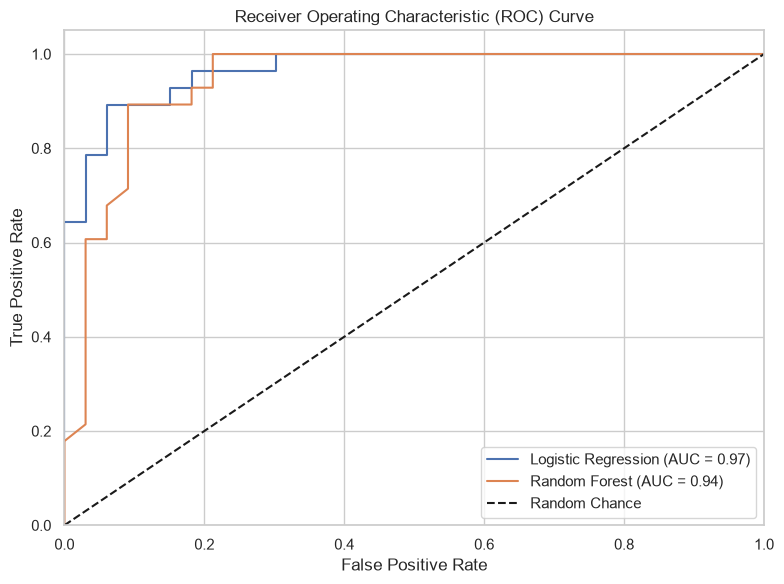

In [12]:

plt.figure(figsize=(8, 6))

for name, model in [('Logistic Regression', logreg_pipeline), ('Random Forest', rf_pipeline)]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('results/roc_curve.png')
plt.show()


## Example Predictions
Let's test the model on a few specific samples from the test set.

In [13]:

example_indices = [0, 1, 2, 3, 4]
example_X = X_test.iloc[example_indices]
example_y_true = y_test.iloc[example_indices].values
example_y_pred = best_model.predict(example_X)
example_y_proba = best_model.predict_proba(example_X)[:, 1]

for i in range(len(example_indices)):
    print(f"Sample {i+1}:")
    print(f"  Actual Disease Status: {'Disease' if example_y_true[i] == 1 else 'No Disease'}")
    print(f"  Predicted Status:      {'Disease' if example_y_pred[i] == 1 else 'No Disease'}")
    print(f"  Prediction Prob:       {example_y_proba[i]:.4f}")
    print("-" * 30)


Sample 1:
  Actual Disease Status: No Disease
  Predicted Status:      No Disease
  Prediction Prob:       0.2093
------------------------------
Sample 2:
  Actual Disease Status: No Disease
  Predicted Status:      Disease
  Prediction Prob:       0.6015
------------------------------
Sample 3:
  Actual Disease Status: No Disease
  Predicted Status:      No Disease
  Prediction Prob:       0.0215
------------------------------
Sample 4:
  Actual Disease Status: No Disease
  Predicted Status:      No Disease
  Prediction Prob:       0.0333
------------------------------
Sample 5:
  Actual Disease Status: No Disease
  Predicted Status:      No Disease
  Prediction Prob:       0.3118
------------------------------


## Save Best Model

In [14]:

model_path = 'models/best_disease_model.pkl'
joblib.dump(best_model, model_path)
print(f"Model saved successfully to {model_path}")


Model saved successfully to models/best_disease_model.pkl


## Reload Saved Model

In [15]:

loaded_model = joblib.load(model_path)
sample = X_test.iloc[[0]]
pred = loaded_model.predict(sample)
print(f"Loaded model prediction for first test sample: {pred[0]}")
assert pred[0] == example_y_pred[0], "Mismatch between original and loaded model predictions!"
print("Model reloading and prediction verified successfully.")


Loaded model prediction for first test sample: 0
Model reloading and prediction verified successfully.


## Save Metrics

In [16]:

best_metrics = results_df.loc[best_model_name]

metrics_text = f"""Dataset: UCI Heart Disease (Processed Cleveland)
Model: {best_model_name}
Accuracy: {best_metrics['Accuracy']:.4f}
Precision: {best_metrics['Precision']:.4f}
Recall: {best_metrics['Recall']:.4f}
F1 Score: {best_metrics['F1']:.4f}
ROC-AUC: {best_metrics['ROC-AUC']:.4f}

Train/Test Split: 80/20
Random State: 42
Selected Model Criterion: Prioritized Recall for medical diagnostic relevance, with overall performance considerations.
"""

with open('results/metrics.txt', 'w') as f:
    f.write(metrics_text)

print("Metrics saved to results/metrics.txt")


Metrics saved to results/metrics.txt


## Conclusion
We successfully built a machine learning pipeline that preprocesses the data, trains multiple models, evaluates their performance, and selects the best one based on recall and ROC-AUC. The pipeline (with preprocessing steps embedded) is saved and ready for deployment.